# Analiza besedil hrvaških trap pesmi

Pri seminarski nalogi iz uvoda v programiranje, sem analiziral besedila pesmi najbolj vplivnih hrvaških trap umetnikov iz strani Genious.com s pomočjo Python knjižnice lyricsgenius. Podatki so shranjeni v datoteki hrvaski_trap_podatki.csv. Ker je hrvaška trap scnene lokalno velika, sem si izbral umetnike Grše, KUKU$, Sjena, Baks, Miach, High 5, BUNTAI in Peki, za katere mislim, da najbolje predstavljajo glasbeni žanr. Od vsakega izvajalca sem s strani Genious izluščil besedila 20 pesmi, ki so po popularnosti najvišje. 

Pri nalogi mi je najprej predstavljala problem izbira izvajalcev, saj jih nekaj ni bilo zaznanih med luščenjem podatkov iz strani, tako da jih je program izpustil pri beleženju. V primeru izvajalca Lokki, ki sem ga žal moral zamenjati, sem pa dobil besedila nemških pesmi, ki pripadajo tujem izvajalcu istega imena. 
Problem mi je predstavljala tudi preobremenitev strežnika. Pri zajemanju večjega števila pesmi preko Genius API-ja je strežnik občasno potreboval preveč časa za odgovor, kar je sprva povzročilo sesutje celotnega programa. Težavo sem rešil tako, da sem v program 1_zajemanje_podatkov.py vgradil zaščito try-except. Če prenos za določenega izvajalca ne uspe, program javi opozorilo, vendar nemoteno nadaljuje z delom za ostale.
Zadnja težava, ki sem jo še imel, so nekatere sklanjatve hrvaških besed. Ko sem po besedilih rabil izluščiti ponovitve določenih besed, sem dobil premalo preštetih, saj se vsaka beseda drugače sklanja (npr. banda, bande, bando). To sem rešil tako, da sem pustil da preišče besede brez pripone, da sem tako lahko preštel vse ponovitve besed, ne glede na to v katerem sklonu so.

## Zajem podatkov iz Genious.com



In [ ]:
import lyricsgenius
import pandas as pd

GENIUS_TOKEN = "BbdyoSFW3Lu4jJ07ODyQxuJ3EY87W2rj0rAlmVg-09stkFl_xsz35TRqUXiSeOGC"

izvajalci_za_analizo = ["Grše", "Peki", "Baks", "BUNTAI", "KUKU$", "Miach", "High 5", "Sjena"]
stevilo_pesmi_na_izvajalca = 20
genius = lyricsgenius.Genius(GENIUS_TOKEN)
genius.remove_section_headers = True 
genius.skip_non_songs = True 
vse_zbrane_pesmi = []


for ime in izvajalci_za_analizo:
    print(f"\nIskanje izvajalca: {ime}")
    try:
        artist = genius.search_artist(ime, max_songs=stevilo_pesmi_na_izvajalca, sort="popularity")
        if artist:
            for song in artist.songs:
                cisto_besedilo = song.lyrics.split("Lyrics", 1)[-1] if "Lyrics" in song.lyrics else song.lyrics
                
                vse_zbrane_pesmi.append({
                    "Izvajalec": artist.name,
                    "Naslov_Pesmi": song.title,
                    "Besedilo": cisto_besedilo
                })
    except Exception as e:
        print(f"Napaka pri prenosu za izvajalca {ime}: {e}")


df = pd.DataFrame(vse_zbrane_pesmi)
df.to_csv("hrvaski_trap_podatki.csv", index=False, encoding="utf-8")

print(f"\nPrenesenih je {len(df)}  pesmi.")
print("Podatki so shranjeni v datoteko 'hrvaski_trap_podatki.csv'.")



Iskanje izvajalca: Grše

Iskanje izvajalca: Peki

Iskanje izvajalca: Baks

Iskanje izvajalca: BUNTAI

Iskanje izvajalca: KUKU$

Iskanje izvajalca: Miach

Iskanje izvajalca: High 5

Iskanje izvajalca: Sjena

Prenesenih je 160  pesmi.
Podatki so shranjeni v datoteko 'hrvaski_trap_podatki.csv'.


## Pregled podatkov

Iz strani Genious.com je bilo prenesenih 160 pesmi, vse z naslovom, imenom avtorja ter besedilom, 20 pesmi na izvajalca. V nadaljevanju bom analiziral rezultate na vprašanja: Kateri izvajalec ima povprečno najdaljše pesmi, kateri izvajalec ima najdaljše naslove, kdo uporablja največ 'trap slenga', kdo uporablja največ kletvic, ter katere so najpogostejše besede od tistih, ki se mi je zdelo, da so 'ključne' v trap sceni, oziroma, katere sem pri sebi opazil, da so uporabljene najpogosteje.


In [16]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("hrvaski_trap_podatki.csv")
print(f"Število pesmi: {len(df)}")

Število pesmi: 160


### Povprečno število besed v pesmi:

Najprej me je zanimalo, kateri od izbranih izvajalcev ima po številu besed najdaljše pesmi. Rezultati so bili pričakovani, saj so med prvimi tisti izvajalci, ki se bolj usmerjajo v "rap", kot so High 5, KUKU$ in Grše, medtem ko so med zadnjimi tisti, katerih pesmi so bolj melodične oz. "komercializirane", npr. Miach in Peki. Buntai in Sjena, ki imata tudi pesmi najbolj raznolikih zvrsti, sta pa kot pričakovano na sredini.

,count,mean,std,min,25%,50%,75%,max
Izvajalec,,,,,,,,
BUNTAI,20.0,408.75,123.15,240.0,298.00,421.0,514.75,615.0
Baks,20.0,273.05,61.23,135.0,246.25,279.5,314.00,382.0
Grše,20.0,441.40,202.17,255.0,306.25,391.0,506.25,1094.0
High 5,20.0,582.65,104.37,438.0,514.75,545.5,648.50,783.0
KUKU$,20.0,454.60,102.43,234.0,376.75,463.5,513.25,620.0
Miach,20.0,239.10,57.46,119.0,211.75,240.0,267.25,356.0
Peki (HRV),20.0,283.65,47.65,193.0,254.75,281.5,316.50,363.0
Sjena,20.0,307.15,82.71,135.0,256.50,299.5,356.25,500.0


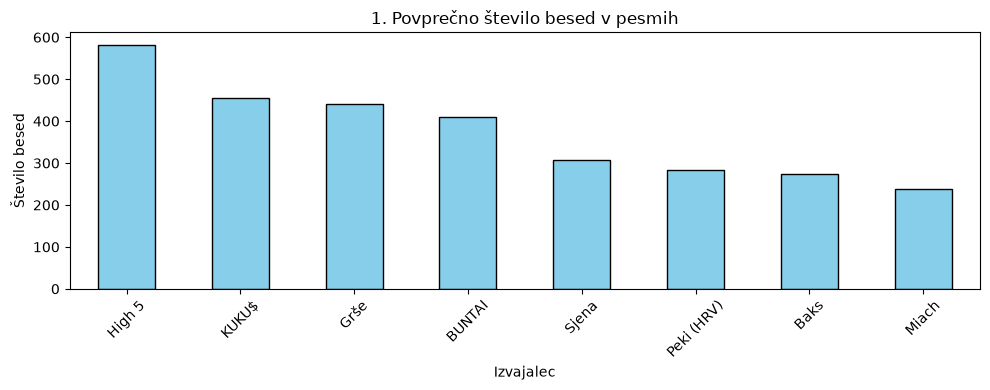

In [17]:
# 1. Povprečno število besed v pesmi

def prestej_vse_besede(besedilo):
    if isinstance(besedilo, str):
        return len(besedilo.split())
    return 0

df["Vse_Besede"] = df["Besedilo"].apply(prestej_vse_besede)

# tabela
statistika_dolzine = df.groupby("Izvajalec")["Vse_Besede"].describe().round(2)
display(statistika_dolzine)

# graf
plt.figure(figsize=(10, 4))
df.groupby("Izvajalec")["Vse_Besede"].mean().sort_values(ascending=False).plot(kind="bar", color="skyblue", edgecolor="black")
plt.title("1. Povprečno število besed v pesmih")
plt.xlabel("Izvajalec")
plt.ylabel("Število besed")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Povprečna dolžina naslovov pesmi

Pri drugem vprašanju me je zanimalo, kateri od glasbenikov ima najdalše naslove. Naslove sem štel po številu znakov, saj nekateri od izvajalcev pogosto v naslovu uporabijo še kakšne simbole ali številke. Najdaljše naslove pesmi ima Peki, medtem ko ima Miach najmanj, kar se mi tudi zdi smiselno, saj ima Miach najpogosteje le enobesedne naslove. Povprečna dolžina naslovov se je med izvajalci razlikovala za največ 6 znakov, kar je kvečjemu lahko le ena beseda, kar je tudi logično, glede na veliko pogostost krajših naslovov v veliki večini zvrsti glasbe.


 2. Povprečna dolžina naslovov pesmi
Izvajalec
Peki (HRV)    11.15
KUKU$         10.80
High 5         9.75
Sjena          9.55
Baks           8.50
BUNTAI         7.95
Grše           7.55
Miach          6.15
Name: Dolzina_Naslova, dtype: float64


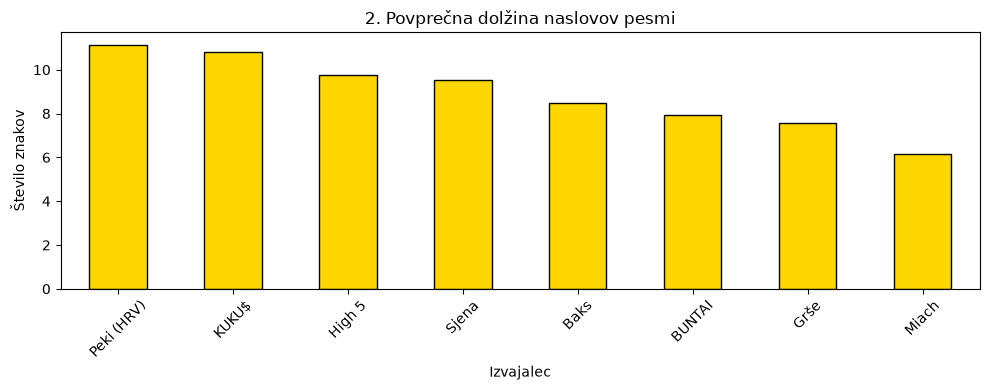

In [18]:
# 2. Povprečna dolžina naslovov pesmi

def dolzina_naslova(naslov):
    if isinstance(naslov, str):
        return len(naslov)
    return 0

stolpec_naslov = "Naslov" if "Naslov" in df.columns else "Naslov_Pesmi"
df["Dolzina_Naslova"] = df[stolpec_naslov].apply(dolzina_naslova)
naslov_povprecje = df.groupby("Izvajalec")["Dolzina_Naslova"].mean().sort_values(ascending=False)

print("\n 2. Povprečna dolžina naslovov pesmi")
print(naslov_povprecje.round(2))

# graf
plt.figure(figsize=(10, 4))
naslov_povprecje.plot(kind="bar", color="gold", edgecolor="black")
plt.title("2. Povprečna dolžina naslovov pesmi")
plt.xlabel("Izvajalec")
plt.ylabel("Število znakov")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Povprečna uporaba "trap slanga"

Tu sem preverjal, kako "stereotipična" besedila imajo posamezni trap izvajalci. Izbral sem besede, za katere menim, da so najpogosteje uporabljene v kontekstu trap scene, še posebej hrvaške, in to so: pare, lova, keš, evro, klub, brat in noć. Pri rezultatih se da opaziti, da umetniki, bolj usmerjeni v rap, bolj uporabljajo izbrane besede, kot pa tisti, ki imajo po navadi pesmi bolj melodične. Izvajalci na vrhu seznama KUKU$, High 5 in Grše so tudi najdlje na sceni od ostalih izvajalcev, tako da lahko predpostavimo, da ima tudi to nek vpliv na izbor besed v besedilu.

,Skupaj,Povprečno
Izvajalec,,
BUNTAI,59,2.95
Baks,39,1.95
Grše,104,5.20
High 5,82,4.10
KUKU$,68,3.40
Miach,41,2.05
Peki (HRV),64,3.20
Sjena,51,2.55


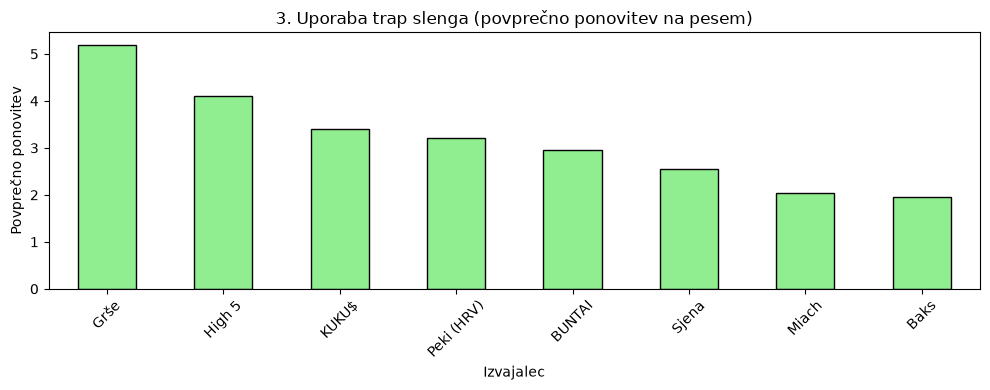

In [19]:
# 3. Uporaba trap slenga

skupne_ponovitve_besed = {"pare": 0, "lova": 0, "keš": 0, "euro": 0, "klub": 0, "brat": 0, "noć": 0}

def analiziraj_trap_sleng(besedilo):
    if not isinstance(besedilo, str):
        return 0
    besedilo_lower = besedilo.lower()
    
    p_pare = besedilo_lower.count("pare")
    p_lova = besedilo_lower.count("lova")
    p_kes = besedilo_lower.count("keš") or besedilo_lower.count("kes")
    p_euro = besedilo_lower.count("euro") or besedilo_lower.count("evro")
    p_klub = besedilo_lower.count("klub")
    p_brat = besedilo_lower.count("brat")
    p_noc = besedilo_lower.count("noć") or besedilo_lower.count("noc")
    
    skupne_ponovitve_besed["pare"] += p_pare
    skupne_ponovitve_besed["lova"] += p_lova
    skupne_ponovitve_besed["keš"] += p_kes
    skupne_ponovitve_besed["euro"] += p_euro
    skupne_ponovitve_besed["klub"] += p_klub
    skupne_ponovitve_besed["brat"] += p_brat
    skupne_ponovitve_besed["noć"] += p_noc
    
    return p_pare + p_lova + p_kes + p_euro + p_klub + p_brat + p_noc

df["Trap_Sleng_Skupaj"] = df["Besedilo"].apply(analiziraj_trap_sleng)

# tabela
tabela_slenga = df.groupby("Izvajalec")["Trap_Sleng_Skupaj"].agg(Skupaj='sum', Povprečno='mean').round(2)
display(tabela_slenga)

# graf
plt.figure(figsize=(10, 4))
df.groupby("Izvajalec")["Trap_Sleng_Skupaj"].mean().sort_values(ascending=False).plot(kind="bar", color="lightgreen", edgecolor="black")
plt.title("3. Uporaba trap slenga (povprečno ponovitev na pesem)")
plt.xlabel("Izvajalec")
plt.ylabel("Povprečno ponovitev")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Uporaba kletvic v pesmih

Tu me je zanimala pogostost uporabe kletvic. Kot pričakovano, so "rapperji" imeli najvišje rezultate, z izjemo Gršeta, ki se je v zadnjih letih usmeril bolj v "mainstream" glasbo, katera je pa ustvarjena za širšo publiko, ki vključuje tudi mlajše poslušalce. Presenetil me je tudi Miachin rezultat, saj v dvajsetih pesmih ni uporabila niti ene kletvice. to si lahko razložimo s tem, da je tema njenih pesmi večinoma ljubezenska.

,Skupaj,Povprečno
Izvajalec,,
BUNTAI,39,1.95
Baks,29,1.45
Grše,46,2.30
High 5,221,11.05
KUKU$,229,11.45
Miach,0,0.00
Peki (HRV),16,0.80
Sjena,42,2.10


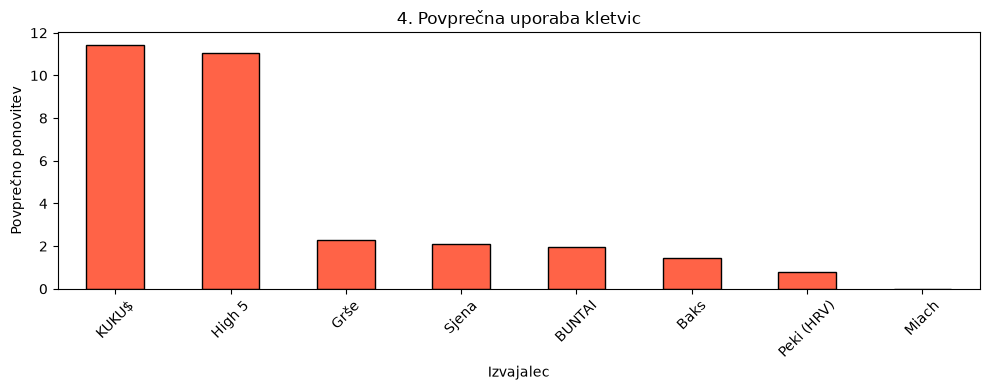

In [20]:
# 4. Uporaba kletvic

def prestej_kletvice(besedilo):
    if not isinstance(besedilo, str):
        return 0
    besedilo_lower = besedilo.lower()
    
    kurva = besedilo_lower.count("kurv")
    sranje = besedilo_lower.count("sranj")
    jebi = besedilo_lower.count("jeb")
    kurac = besedilo_lower.count("kurac") + besedilo_lower.count("kurc")
    boga = besedilo_lower.count("boga")
    mater = besedilo_lower.count("mater")
    kmica = besedilo_lower.count("kmic")
    
    return kurva + sranje + jebi + kurac + boga + mater + kmica

df["Kletvice_Skupaj"] = df["Besedilo"].apply(prestej_kletvice)

# tabela
tabela_kletvic = df.groupby("Izvajalec")["Kletvice_Skupaj"].agg(Skupaj='sum', Povprečno='mean').round(2)
display(tabela_kletvic)

# graf
plt.figure(figsize=(10, 4))
df.groupby("Izvajalec")["Kletvice_Skupaj"].mean().sort_values(ascending=False).plot(kind="bar", color="tomato", edgecolor="black")
plt.title("4. Povprečna uporaba kletvic")
plt.xlabel("Izvajalec")
plt.ylabel("Povprečno ponovitev")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Skupna pogostost izbranih besed

Zadnje me je pa še zanimalo, katera od besed, za katere sem se pri 3. vprašanju odločil, da predstavljajo trap sceno, je uporabljena najpogosteje, ne glede na izvajalca. Ta beseda je bila noć, ki je pa tudi pogosta izven konteksta glasbe, ima pa močan pomen v hrvaškem trapu, saj je tematika trapa že posebi bolj temačna in ker za večino pesmi velja, da se "dogajajo ponoči". Če bi pa združil ponovitve sopomenk denarja, bi pa močno presegle pogostost noči, saj se izvajalci v svojih besedilih pogosto "bahajo" s tem, koliko denarja imajo, kar je pa največkrat vidno ravno v rap in trap pesmih.

In [21]:
# 5. Pogostost izbranih besed

print("\nSKUPNA POGOSTOST IZBRANIH BESED")

df_besede = pd.DataFrame(list(skupne_ponovitve_besed.items()), columns=['Ključna beseda', 'Število ponovitev'])
df_besede = df_besede.sort_values(by='Število ponovitev', ascending=False).reset_index(drop=True)
display(df_besede)


SKUPNA POGOSTOST IZBRANIH BESED


,Ključna beseda,Število ponovitev
0,noć,147
1,pare,132
2,brat,96
3,keš,69
4,klub,49
5,lova,9
6,euro,6


## Zaključek

Pri seminarski nalogi sem ugotovil, da ima hrvaška trap scena vseeno dosti raznoliko strukturo besedil, ki je odvisna od tega, v katero podzvrst trapa spada, ter predvsem od glasbenega stila izvajalca in njegove identitete. Pomembno se je zavedati, da je hrvaška scena zelo velika, tako da bi statistikam pomagala čim večja izbira izvajalcev in pesmi. Pri izračunu povprečne dolžine besedil, bi lahko s pomočjo Spotify-ja dodal še časovno trajanje pesmi, da bi lahko dodal še "povprečno hitrost rapanja/petja", ki bi prineslo več podatkov in razumevanja, kako izbrani izvajalci pišejo.